# Анализ открытий экзопланет: динамика, обсерватории и орбитальные периоды

**Выполнили студенты группы БГЕО251:** Гущина Анна и Баяндина Анастасия.

## Введение
Современная астрономия активно изучает экзопланеты - планеты за пределами Солнечной системы. База данных NASA Exoplanet Archive содержит десятки тысяч записей о них. Однако статистика открытий зависит от физики космоса и от технологий: какие телескопы запущены, как долго они работают и какие методы используются. В этом проекте мы анализируем массив данных, чтобы понять, как человечество открывает новые миры.

## Цель исследования
Выявить основные закономерности в открытии экзопланет: определить динамику открытий по годам, найти самые продуктивные обсерватории и проанализировать распределение орбитальных периодов.

## Задачи:
1. Загрузить данные из NASA Exoplanet Archive и очистить их от пропусков.
2. Построить график количества открытых планет по годам.
3. Определить Топ-10 телескопов/обсерваторий по числу открытий.
4. Построить гистограмму распределения орбитальных периодов.
5. Сделать выводы о том, как методы наблюдения влияют на наши знания о Вселенной.


### 1. Загрузка и первичная обработка данных

Для работы используется открытый API NASA Exoplanet Archive. Мы загружаем таблицу подтвержденных экзопланет (PS) в формате CSV напрямую по ссылке. Это обеспечивает воспроизводимость кода - актуальные данные скачаются сами, без необходимости вручную скачивать файлы. 

Для удобства данные сохраняются в локальный файл `confirmed_planets.csv`, чтобы при повторных запусках не нагружать сервер архива.

In [7]:
import pandas as pd

url = "https://exoplanetarchive.ipac.caltech.edu/TAP/sync?query=select+*+from+ps&format=csv"
df = pd.read_csv(url)

df.to_csv("confirmed_planets.csv", index=False)

print(f"Готово! Загружено {len(df)} строк.")

C:\Users\user\AppData\Local\Temp\ipykernel_12524\988389763.py:4: DtypeWarning: Columns (0: pl_occdepstr, 1: pl_trueobliqstr, 2: sy_icmagstr) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(url)


Готово! Загружено 40350 строк.


### 2. Подготовка данных и анализ динамики открытий

Для построения графиков мы оставляем только нужные нам колонки: 
* `disc_year` — год открытия;
* `disc_facility` — обсерватория или телескоп;
* `discoverymethod` — метод обнаружения.

Все строки с пропущенными значениями удаляются, чтобы графики строились корректно.

**График 1:** показывает общее количество открытых экзопланет по годам. По нему можно отследить историю развития космических миссий.
**График 2:** горизонтальная диаграмма, отображающая Топ-10 обсерваторий по числу открытий. Ось Y инвертирована (`invert_yaxis`), чтобы лидер по открытиям находился в самом верху для удобства чтения.

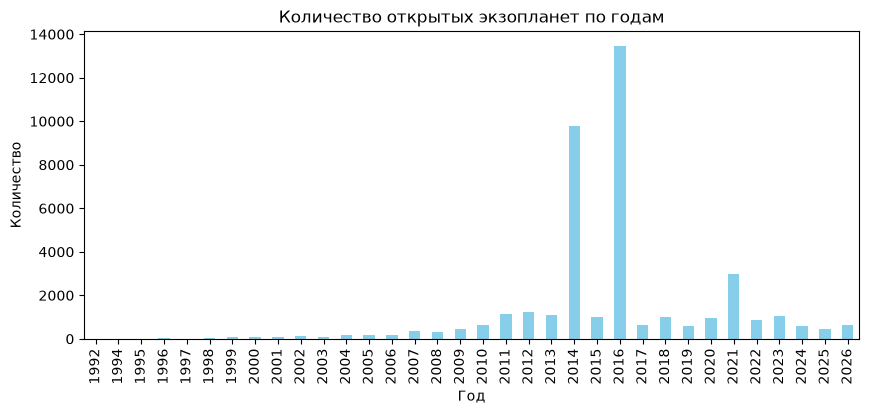

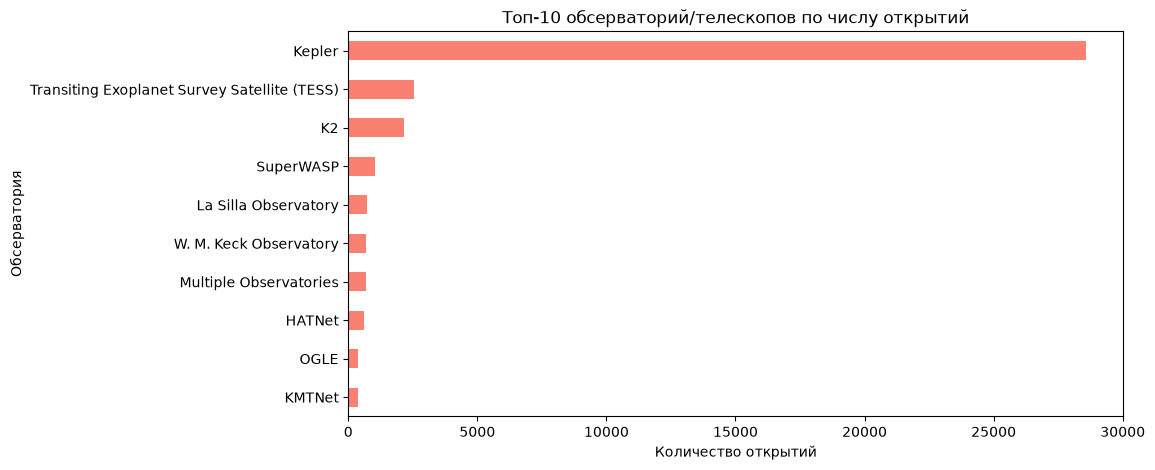

In [10]:
import matplotlib.pyplot as plt

df = pd.read_csv("confirmed_planets.csv", low_memory=False)
df_clean = df[["disc_year", "disc_facility", "discoverymethod"]].dropna()
plt.figure(figsize=(10, 4))
df_clean["disc_year"].value_counts().sort_index().plot(kind="bar", color="skyblue")
plt.title("Количество открытых экзопланет по годам")
plt.xlabel("Год")
plt.ylabel("Количество")
plt.show()

plt.figure(figsize=(10, 5))
df_clean["disc_facility"].value_counts().head(10).plot(kind="barh", color="salmon")
plt.title("Топ-10 обсерваторий/телескопов по числу открытий")
plt.xlabel("Количество открытий")
plt.ylabel("Обсерватория")
plt.gca().invert_yaxis()
plt.show()

### 3. Анализ орбитальных периодов

Орбитальный период (`pl_orbper`) - это время, за которое планета совершает полный оборот вокруг своей звезды (в днях). Мы строим гистограмму распределения периодов. 

*Примечание:* используется логарифмическая шкала по оси Y (`log=True`), так как количество планет с короткими периодами в сотни раз превышает количество планет с длинными периодами.

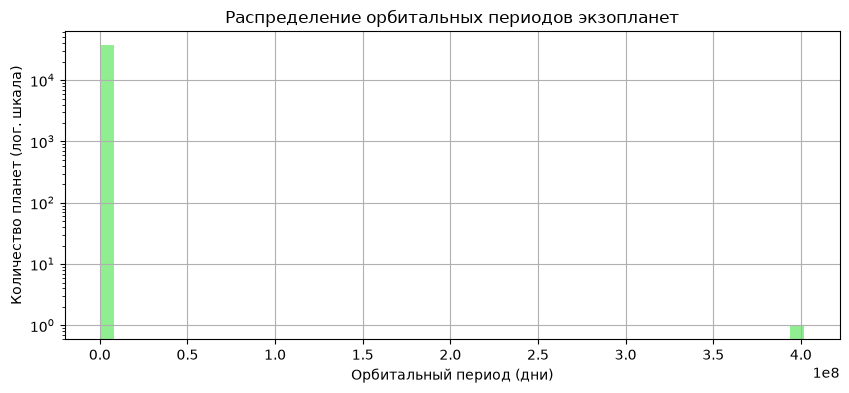

In [9]:
plt.figure(figsize=(10, 4))

df_clean_period = df["pl_orbper"].dropna()
df_clean_period.hist(bins=50, log=True, color="lightgreen")

plt.title("Распределение орбитальных периодов экзопланет")
plt.xlabel("Орбитальный период (дни)")
plt.ylabel("Количество планет (лог. шкала)")
plt.show()

## Выводы по полученным данных

В ходе исследования мы проанализировали массив данных об экзопланетах. 

1. **Связь между методами и количеством открытий, о чём нам говорят данные первого и второго графика:** 
   Резкий скачок количества открытий в 2014 и 2016 годах напрямую связан с пиком работы космического телескопа **Kepler**, который является абсолютным лидером по числу находок. Это доказывает, что появление специализированных космических миссий радикально ускорило темпы открытий по сравнению с наземными обсерваториями (SuperWASP, La Silla и др.).

2. **Чем же обусловленны достаточно спицифические результаты третьего графика:**
   Гистограмма орбитальных периодов показывает, что подавляющее большинство известных нам экзопланет имеют короткие периоды (от 1 до 100 дней). Это не значит, что в космосе нет планет с длинными периодами, просто метод, который мы выбрали, работает по принципу чем ближе планета к звезде, тем чаще она проходит по её диску и тем легче её обнаружить.

**Общий итог:** Современная статистика экзопланет, огромный вклад телескопов вроде Kepler и преобладание планет с короткими орбитами, это не  отражение устройства Вселенной напрямую, а скорее отражение возможностей известныхнам методов наблюдения и созданых человечеством приборов  на данном уровне развития нашей цивилизации.